# Forecasting GMTIFS-like shear S/N (AO-fed NIR IFU, GMT)

**README.md Phase 7: "GMTIFS-like forecast."** `kino/config/gmtifs.yaml` is a
fiducial (not as-built) AO-fed near-IR IFU config -- 25-50 mas spaxels, R~5-10k,
0.9-2.5 um -- for Halpha/[O III] kinematics of z~0.4-1.5 background discs. This
notebook forecasts it at a real site (`kino.observing.GMT`, added this session
from GMTO's own published coordinates -- see that module's docstring) and finds,
building it, three real and generalizable limitations in KINO's current
forecast machinery for *any* AO-fed NIR instrument, not just this one:

1. `forecast_ifu`/`forecast_slit` always convert a swept ground-based seeing
   value into the instrument's PSF (`kino.analysis.forecast._forecast`:
   `PSF(seeing_fwhm=seeing_at(...))`, unconditionally) -- there is no way to
   hold an AO-corrected PSF fixed and forecast through a night with it. Using
   the convenience wrapper on an AO system would silently apply ground-seeing
   physics to it.
2. `kino.observing.skymodel`'s sky spectrum library is built from Paranal
   SkyCalc output out to 1 micron only -- `gmtifs.yaml`'s own window
   (1.10-1.14 um) is past that edge.
3. `kino.observing.extinction`'s CTIO curve ends at 1087 nm -- also past this
   window.

None of these are bugs; all are already-documented scope limits (CLAUDE.md:
"optical only," "the near-infrared is not supported yet") that this notebook
is the first thing in the project to actually run into. So instead of the
seeing/night-resolved forecast `notebooks/10_sifs_forecast.ipynb`/
`11_goodman_forecast.ipynb` show, this one calls
`kino.analysis.fisher.shear_fisher` directly at `gmtifs.yaml`'s own fixed
fiducial AO PSF and sky rate -- still real, still the same Cramer-Rao bound
machinery, just not swept through conditions the pipeline can't yet model for
this regime.

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.utils.iers import conf as iers_conf
from kino_style import AQUA, BLUE, ORANGE

from kino.analysis.fisher import shear_fisher
from kino.galaxy import DiscGalaxy
from kino.instruments.ifu import IFU
from kino.observing import GMT, moon_state, night_window, target_track

# If this environment can't reach the IERS Earth-orientation data service,
# astropy's bundled table can be too stale for precise Time/AltAz transforms
# at a future date and raise rather than degrade gracefully -- this relaxes
# that check (sub-arcsecond-level precision only; negligible for airmass).
iers_conf.auto_max_age = None

gmtifs = IFU.from_config("../kino/config/gmtifs.yaml")
night = night_window(GMT, "2027-07-15")
print(f"night {night.start.iso[:16]} -> {night.end.iso[:16]} UT ({night.duration:.1f})")
print(f"GMT site: {GMT.latitude:.4f}, {GMT.longitude:.4f}, {GMT.location.height:.0f}")

night 2027-07-15 23:27 -> 2027-07-16 10:07 UT (10.7 h)
GMT site: -29.0483 deg, -70.6836 deg, 2514 m


## 1. A representative background disc

A single synthetic target (not from any real or private list), matching
`gmtifs.yaml`'s own documented example: a disc at $z=0.68$, Halpha redshifted
into the config's 1.10-1.14 um window.

In [2]:
coord = SkyCoord("19h43m00s", "-19d00m00s")  # near-transit at GMT mid-night, offset from zenith
Z = 0.68
LINE_REST = 0.65628 * u.um
line_wavelength_obs = LINE_REST * (1 + Z)
print(f"Halpha observed at {line_wavelength_obs.to(u.um):.4f}")

galaxy = DiscGalaxy(r_e=0.25, inc=55.0, pa=30.0, v_flat=180.0, z=Z, sigma0=40.0)
G = (0.04, 0.0)
LINE_FLUX = 1e-15 * u.erg / u.s / u.cm**2

Halpha observed at 1.1026 um


## 2. Real visibility through a real GMT night

Airmass and moon geometry are pure celestial mechanics -- they don't depend on
the sky-spectrum/extinction gaps above, so this part of the forecast is as
real for GMT as it is for SOAR.

best airmass 1.02 at hour 5.0
usable (airmass<=2) window: 12/13 sampled times


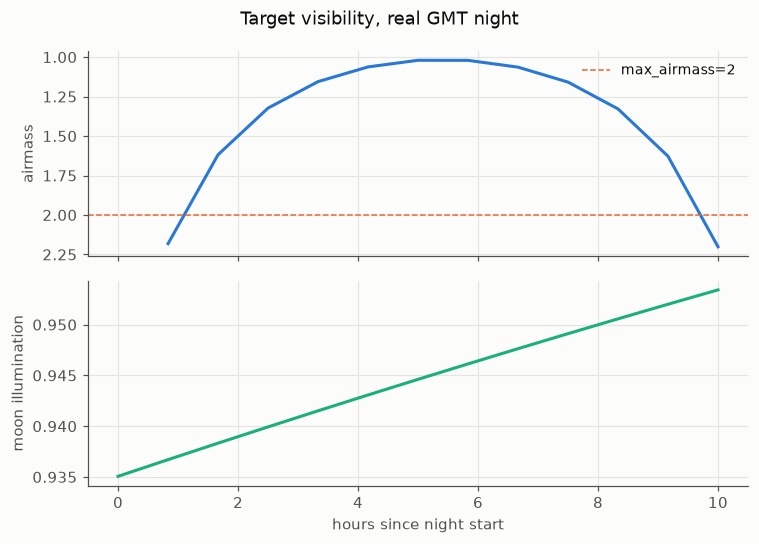

In [3]:
times = night.times[::10]
track = target_track(GMT, coord, times)
moon = moon_state(GMT, times, coord)
hours = (times - night.start).to_value(u.hour)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
ok = np.isfinite(track.airmass) & (track.airmass <= 3)
a1.plot(hours[ok], track.airmass[ok], color=BLUE)
a1.axhline(2.0, color=ORANGE, ls="--", lw=1, label="max_airmass=2")
a1.set_ylabel("airmass")
a1.invert_yaxis()
a1.legend()
a2.plot(hours, moon.illumination, color=AQUA)
a2.set_ylabel("moon illumination")
a2.set_xlabel("hours since night start")
fig.suptitle("Target visibility, real GMT night")
fig.tight_layout()

best = np.nanargmin(np.where(ok, track.airmass, np.inf))
print(f"best airmass {track.airmass[best]:.2f} at hour {hours[best]:.1f}")
print(f"usable (airmass<=2) window: {ok.sum()}/{len(ok)} sampled times")

## 3. Shear precision at the fixed fiducial AO PSF

`gmtifs.yaml`'s own `seeing_fwhm: 0.05 arcsec` (fiducial AO-corrected residual
core width) and `sky_electron_rate: 3 electron/s` (generic NIR fiducial,
*not* modelled from the real GMT/Las Campanas sky) are used as given --
unlike the SIFS/Goodman notebooks, neither is swept or computed from
real conditions, for the reasons in the intro.

In [4]:
result = shear_fisher(
    gmtifs,
    galaxy,
    line_flux=LINE_FLUX,
    line_wavelength=LINE_REST,
    g=G,
    estimator="cube",
)
print(f"line S/N (whole field): {result.line_snr:.1f}")
print(f"median per-spaxel S/N: {result.median_spaxel_snr:.2f}  ({result.n_spaxels} spaxels)")
print(f"sigma_g (fixed nuisance):      {np.round(result.sigma_fixed, 4)}")
print(f"sigma_g (marginal nuisance):   {np.round(result.sigma_marginal, 4)}")

line S/N (whole field): 55.5
median per-spaxel S/N: 8.20  (202 spaxels)
sigma_g (fixed nuisance):      [0.0008 0.0008]
sigma_g (marginal nuisance):   [0.0041 0.0069]


## 4. Flux scan: what limits the precision

Fully meaningful without the sky/extinction model gap above, since both PSF
and sky are held fixed throughout -- only the source brightness varies.

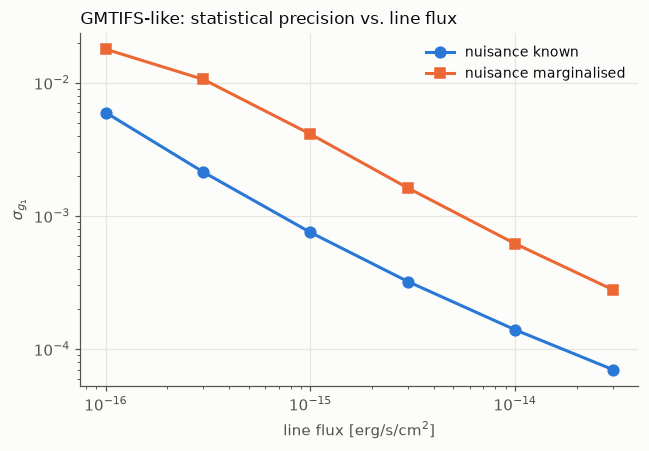

In [5]:
fluxes = np.array([1e-16, 3e-16, 1e-15, 3e-15, 1e-14, 3e-14])
sig_fixed, sig_marg = [], []
for f in fluxes:
    r = shear_fisher(
        gmtifs,
        galaxy,
        line_flux=f * u.erg / u.s / u.cm**2,
        line_wavelength=LINE_REST,
        g=G,
        estimator="cube",
    )
    sig_fixed.append(r.sigma_fixed[0])
    sig_marg.append(r.sigma_marginal[0])

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.loglog(fluxes, sig_fixed, "o-", color=BLUE, label="nuisance known")
ax.loglog(fluxes, sig_marg, "s-", color=ORANGE, label="nuisance marginalised")
ax.set_xlabel("line flux [erg/s/cm$^2$]")
ax.set_ylabel("$\\sigma_{g_1}$")
ax.set_title("GMTIFS-like: statistical precision vs. line flux")
ax.legend()
fig.tight_layout()

## Known limitations (carry into any real GMTIFS use)

- **No AO-aware forecast sweep.** `forecast_ifu`/`forecast_slit` always apply
  ground-seeing Kolmogorov scaling to the swept `seeing_ref` and overwrite the
  instrument's own PSF with it -- there is currently no way to forecast *through
  a night* at a fixed AO-corrected PSF using the high-level convenience
  functions; this notebook works around it by calling `shear_fisher` directly
  at a single fixed PSF instead. A real fix would add a fixed-PSF / "AO mode"
  to `_forecast` -- not attempted here, to keep this a focused case-study
  notebook rather than a forecast-machinery change.
- **No real NIR sky model.** `kino.observing.skymodel`'s library covers
  Paranal SkyCalc output to 1 micron; `gmtifs.yaml`'s own window (1.10-1.14 um)
  is past that edge, so `sky_electron_rate` above is the config's own generic
  fiducial, not modelled from real conditions (and GMT is at Las Campanas, not
  Paranal, an additional cross-site gap already documented for the optical
  SOAR/Pachon configs).
- **No real NIR extinction model.** The CTIO curve ends at 1087 nm.
- `gmtifs.yaml` itself is explicitly fiducial throughout (its own header), not
  GMTIFS's as-built specification -- see `kino/config/gmtifs.yaml`.
- The AO PSF itself is a single effective Gaussian width, not a real
  core+halo/Strehl model -- the same documented simplification as
  `kino/config/gemini_nifs.yaml`/`keck_osiris.yaml`.